# Лабораторная работа №3. Декомпозиция временных рядов (Практика к Лекции 2)

**Цель:** применить классическую декомпозицию, STL и MSTL на одном ряду со сложной сезонностью (суточной и недельной), сравнить качество выделения компонент и интерпретировать результаты.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.graphics.tsaplots import plot_acf
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 5)

In [2]:
np.random.seed(42)
n = 1000 # около 41 дня
t = np.arange(n, dtype=float)

# Тренд
trend = 0.01 * t
# Суточная сезонность (24)
daily = 5 * np.sin(2 * np.pi * t / 24)
# Недельная сезонность (168)
weekly = 10 * np.sin(2 * np.pi * t / 168)
# Шум
noise = np.random.randn(n)

values = trend + daily + weekly + noise

# Небольшой сдвиг уровня (структурный сдвиг)
values[500:] += 15

# Добавляем несколько выбросов
outlier_idx = [100, 250, 600, 800, 950]
for idx in outlier_idx:
    values[idx] += np.random.choice([-30, 30])

# Создаем Pandas Series с почасовым индексом
ts = pd.Series(values, index=pd.date_range("2026-01-01", periods=n, freq="h"))

print("Ряд успешно сгенерирован.")

Ряд успешно сгенерирован.


## 1. Визуальный анализ и ACF
Построим график ряда, подсерии (по дням и неделям), heatmap и автокоррелограмму, чтобы подтвердить наличие двух сезонностей.

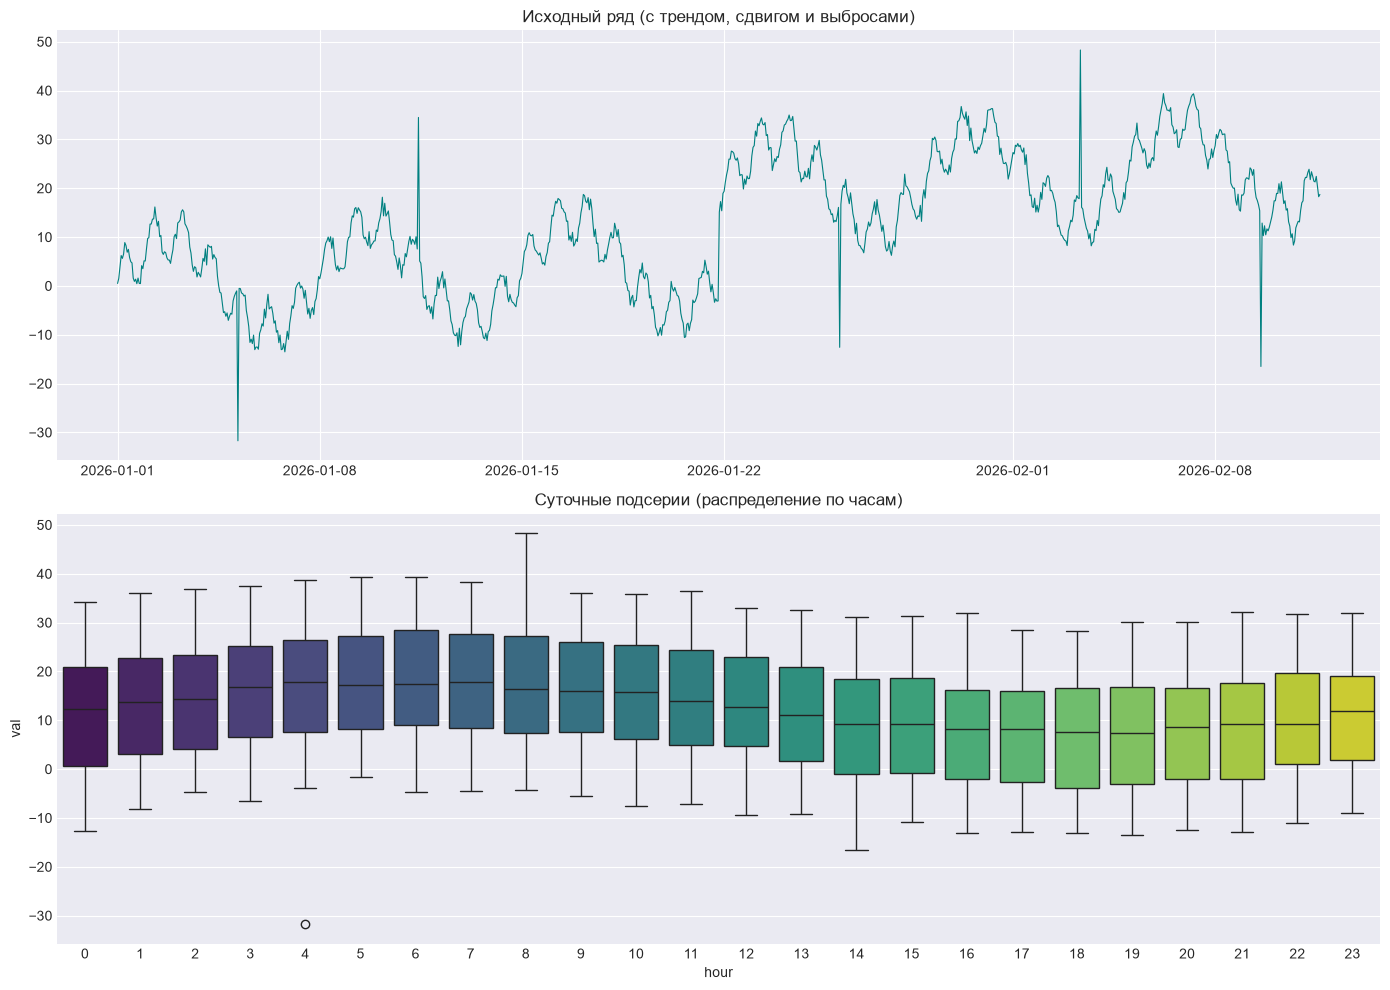

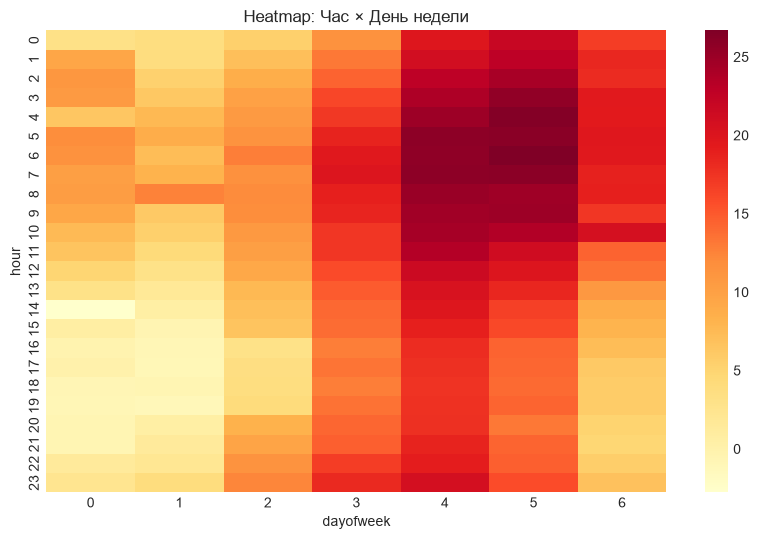

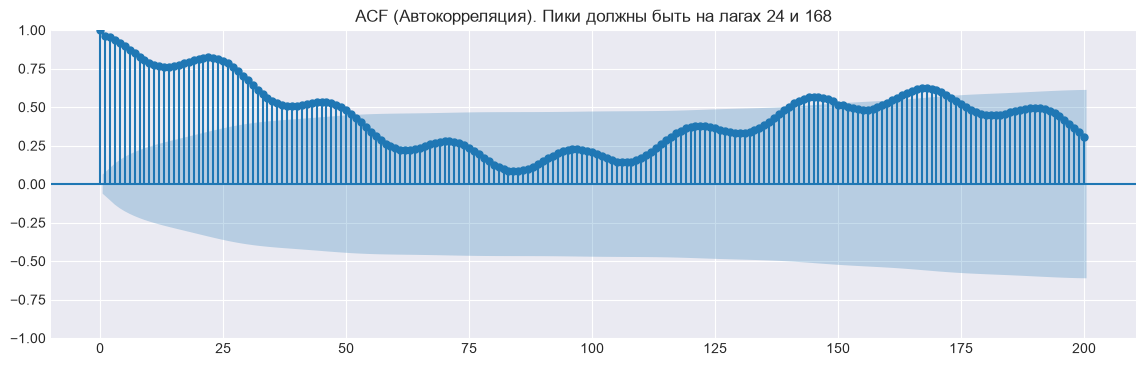

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Весь ряд
axes[0].plot(ts.index, ts.values, color='teal', linewidth=0.8)
axes[0].set_title('Исходный ряд (с трендом, сдвигом и выбросами)')

# Подсерии (средние значения по часам и дням недели)
df_plot = pd.DataFrame({'val': ts}, index=ts.index)
df_plot['hour'] = df_plot.index.hour
df_plot['dayofweek'] = df_plot.index.dayofweek

sns.boxplot(x='hour', y='val', data=df_plot, ax=axes[1], palette='viridis')
axes[1].set_title('Суточные подсерии (распределение по часам)')

plt.tight_layout()
plt.show()

# Heatmap "час x день недели"
pivot = df_plot.pivot_table(index='hour', columns='dayofweek', values='val', aggfunc='mean')
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, cmap='YlOrRd')
plt.title('Heatmap: Час × День недели')
plt.show()

# ACF
plt.figure(figsize=(14, 4))
plot_acf(ts, lags=200, ax=plt.gca())
plt.title('ACF (Автокорреляция). Пики должны быть на лагах 24 и 168')
plt.show()

## 2. Сравнение методов декомпозиции
Применим три метода: классический (period=24), STL (period=24) и MSTL (periods=(24, 168)).

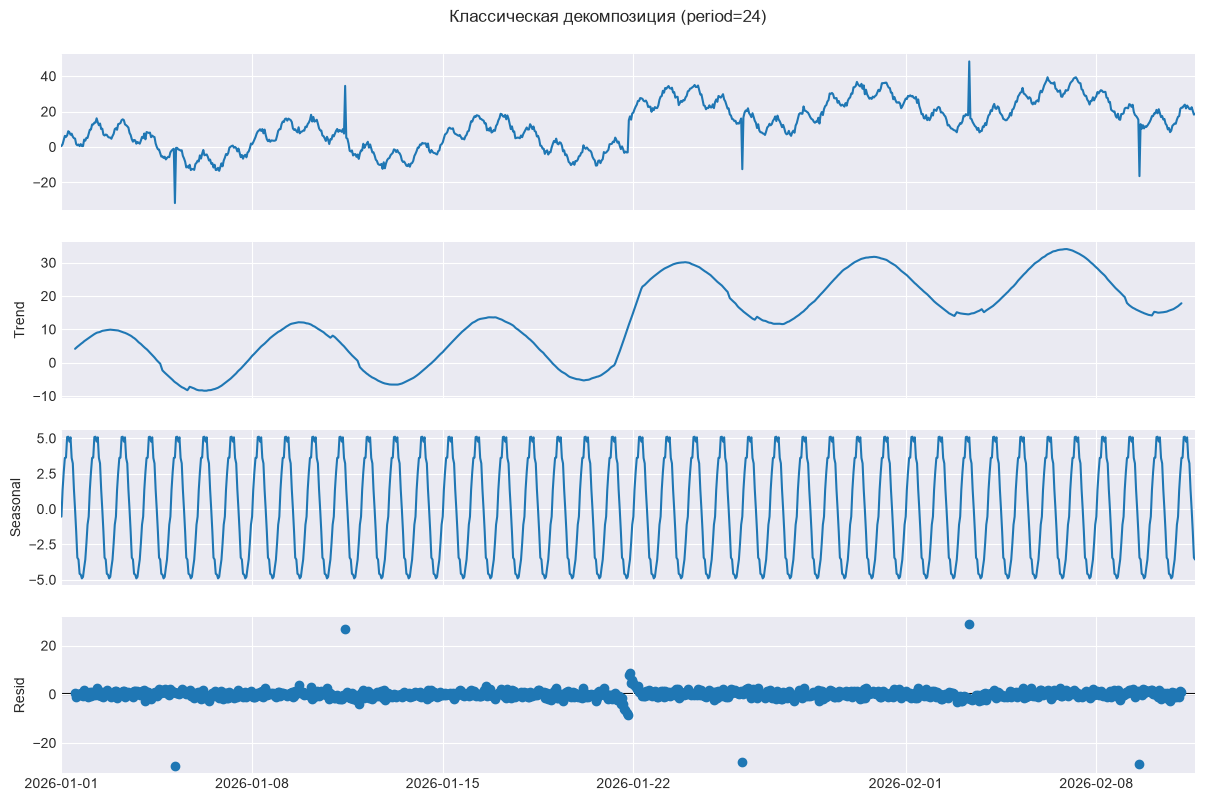

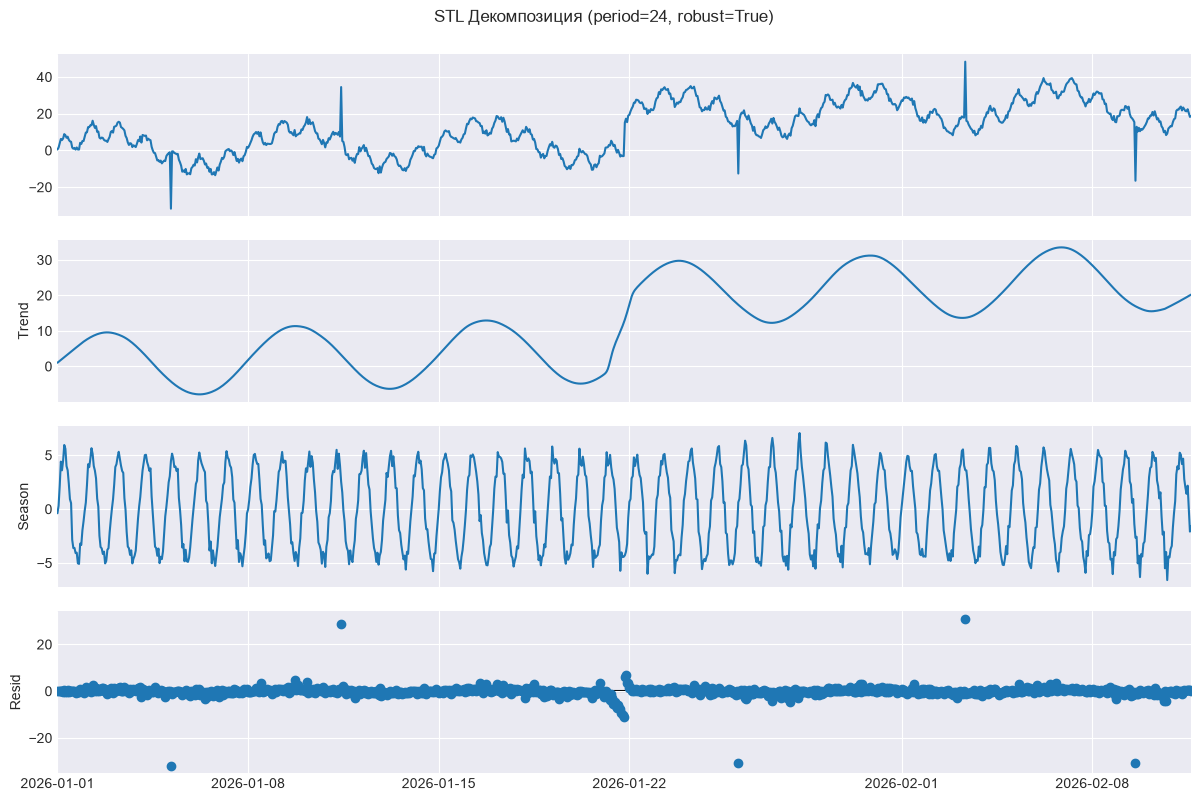

In [4]:
# 1. Классическая декомпозиция с period=24
res_classic = seasonal_decompose(ts, model='additive', period=24)
fig = res_classic.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Классическая декомпозиция (period=24)', y=1.02)
plt.show()

# 2. STL с period=24
stl = STL(ts, period=24, robust=True)
res_stl = stl.fit()
fig = res_stl.plot()
fig.set_size_inches(12, 8)
fig.suptitle('STL Декомпозиция (period=24, robust=True)', y=1.02)
plt.show()

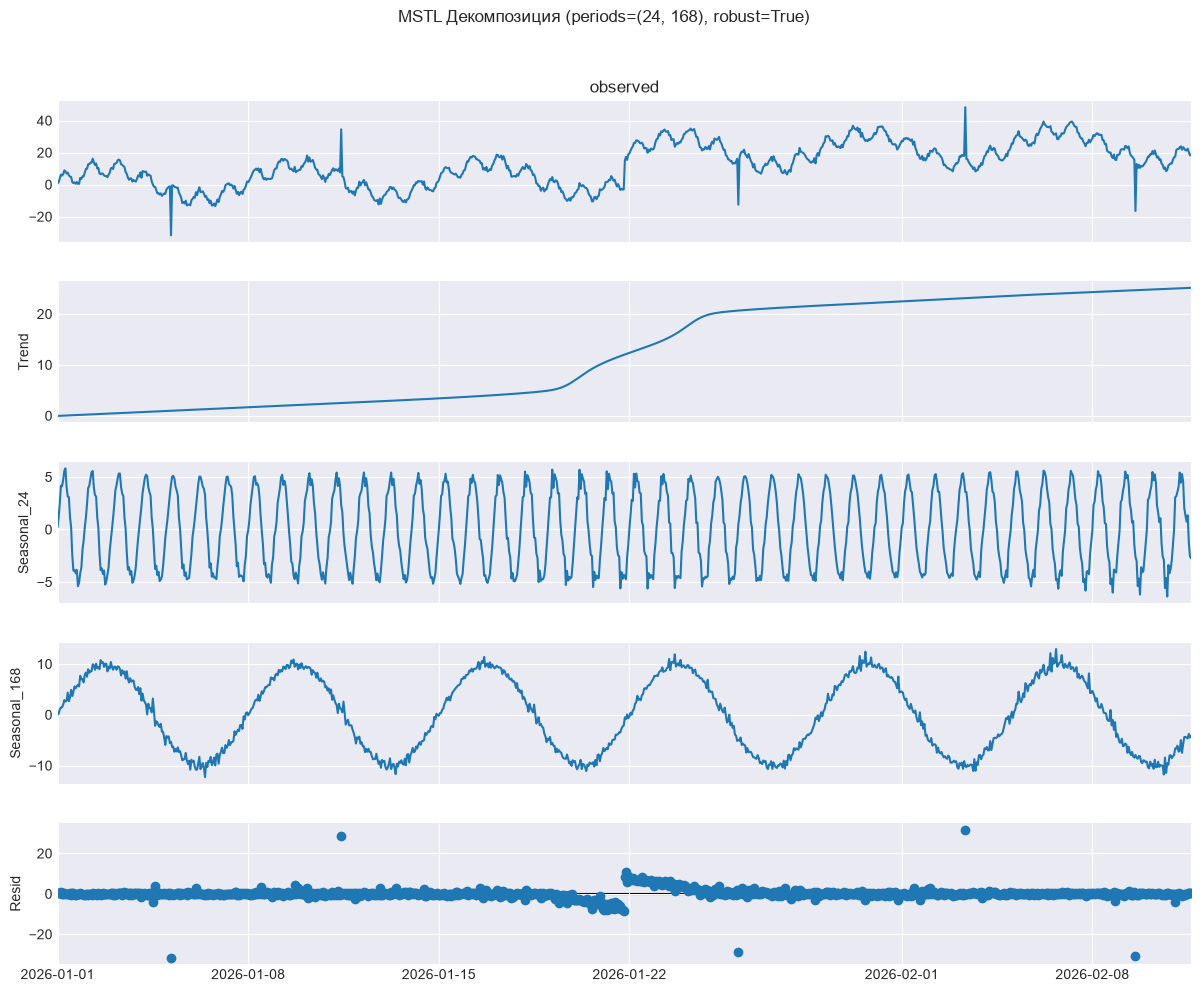

In [5]:
# 3. MSTL с periods=(24, 168)
mstl = MSTL(ts, periods=(24, 168), stl_kwargs={"robust": True})
res_mstl = mstl.fit()
fig = res_mstl.plot()
fig.set_size_inches(12, 10)
fig.suptitle('MSTL Декомпозиция (periods=(24, 168), robust=True)', y=1.02)
plt.show()

## 3. Количественное сравнение остатков
Сравним дисперсию остатков и наличие автокорреляции на лагах 24 и 168 для каждого метода.

=== ДИСПЕРСИЯ ОСТАТКОВ ===
Классическая: 5.8094
STL:          6.3900
MSTL:         8.4882
Чем меньше дисперсия, тем чище остаток.



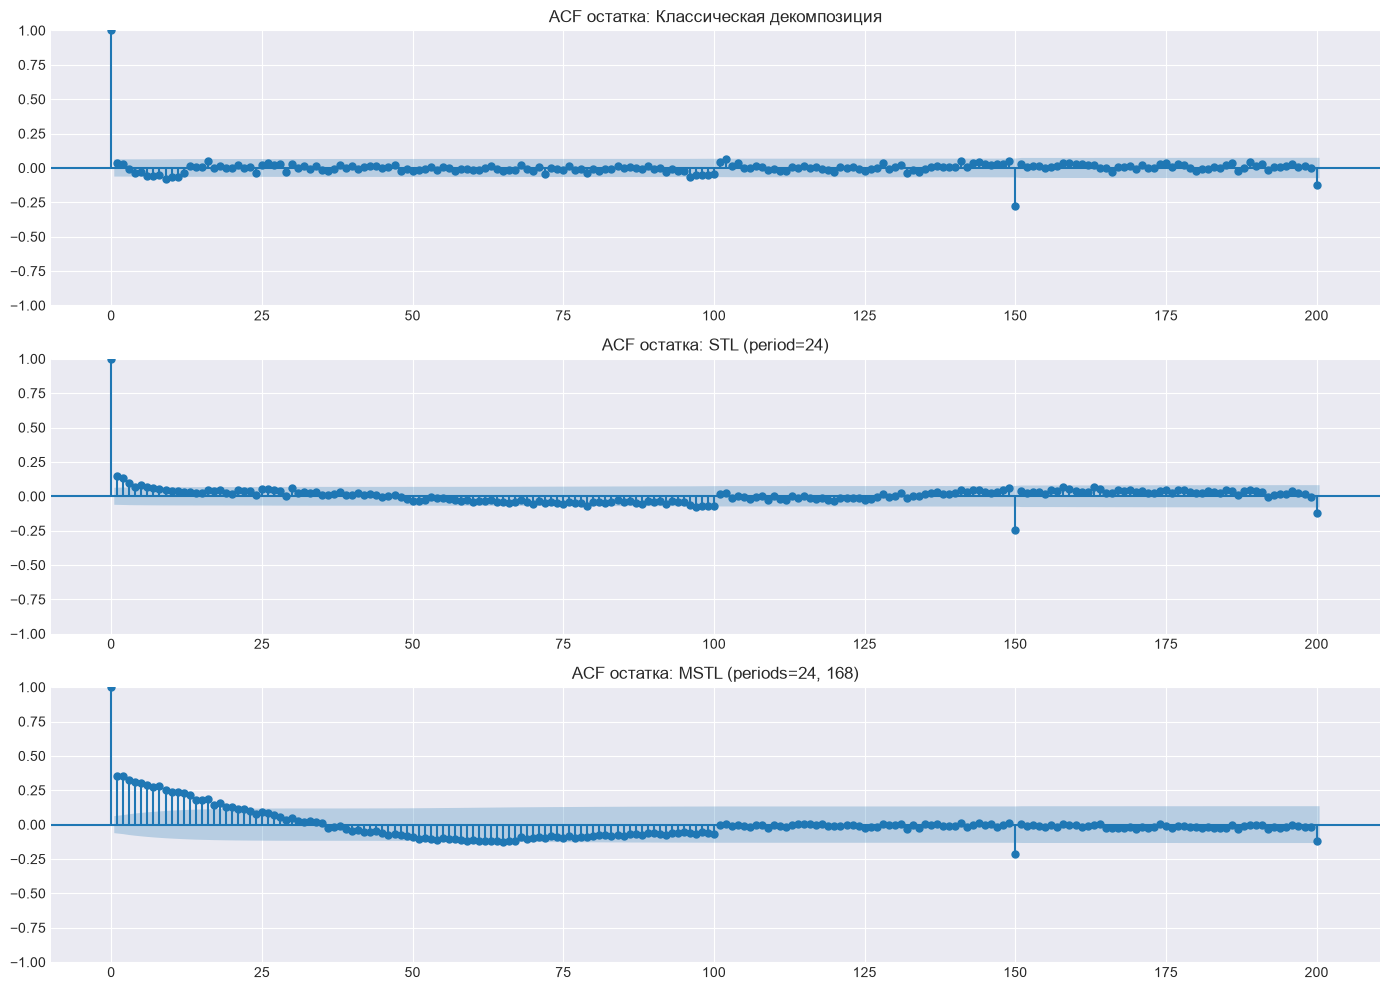

In [6]:
# Сбор остатков
resid_classic = res_classic.resid.dropna()
resid_stl = res_stl.resid.dropna()
resid_mstl = res_mstl.resid.dropna()

print("=== ДИСПЕРСИЯ ОСТАТКОВ ===")
print(f"Классическая: {np.var(resid_classic):.4f}")
print(f"STL:          {np.var(resid_stl):.4f}")
print(f"MSTL:         {np.var(resid_mstl):.4f}")
print("Чем меньше дисперсия, тем чище остаток.\n")

# ACF остатков
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
plot_acf(resid_classic, lags=200, ax=axes[0], title='ACF остатка: Классическая декомпозиция')
plot_acf(resid_stl, lags=200, ax=axes[1], title='ACF остатка: STL (period=24)')
plot_acf(resid_mstl, lags=200, ax=axes[2], title='ACF остатка: MSTL (periods=24, 168)')
plt.tight_layout()
plt.show()

# Домашнее задание к Лекции 2: Декомпозиция временных рядов

**1. Выбранный ряд:** Синтетический месячный ряд (144 точки = 12 лет), имитирующий пассажиропоток авиакомпании (аналог датасета AirPassengers). Содержит тренд и сезонность.

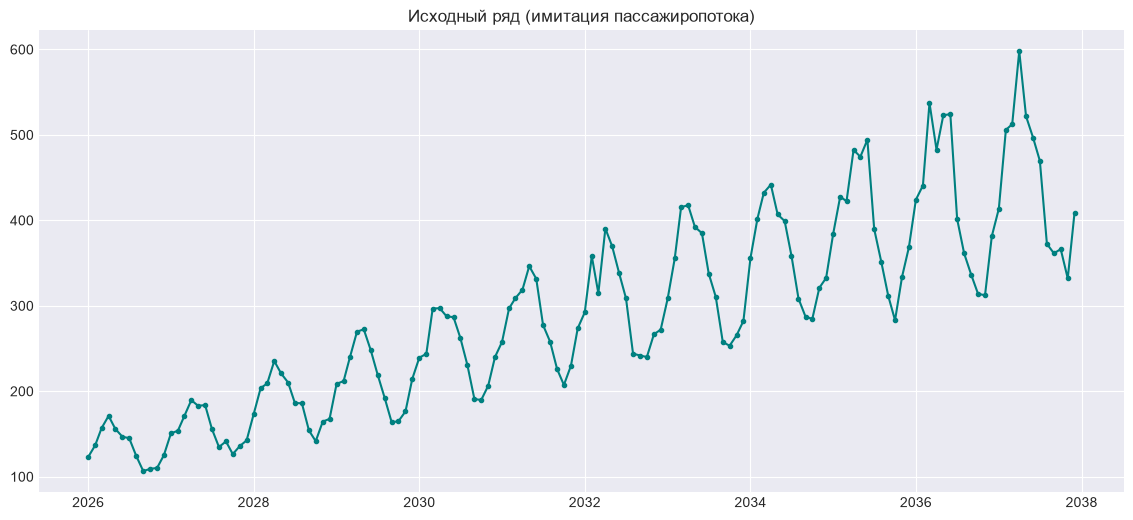

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.graphics.tsaplots import plot_acf
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 6)

# Генерируем 12 лет данных (144 месяца)
np.random.seed(42)
n = 144
t = np.arange(n)

# Линейный тренд
trend = 100 + 2 * t

# Мультипликативная сезонность (период 12 месяцев)
# Амплитуда сезонности растет вместе с трендом
seasonality = 1.2 + 0.3 * np.sin(2 * np.pi * t / 12)

# Шум
noise = np.random.normal(1.0, 0.05, n)

# Итоговый ряд (мультипликативная модель: T * S * R)
values = trend * seasonality * noise

# Создаем Pandas Series
ts = pd.Series(values, index=pd.date_range("2026-01-01", periods=n, freq="MS"))

plt.plot(ts, marker='o', markersize=3, color='teal')
plt.title('Исходный ряд (имитация пассажиропотока)')
plt.show()

**2. Обоснование выбора модели:**
Судя по графику, с течением времени (по мере роста тренда) **амплитуда сезонных колебаний увеличивается**. Зимние и летние пики становятся все более высокими в абсолютных значениях. 
Это классический признак **мультипликативной модели** ($y_t = T_t \cdot S_t \cdot R_t$). Если бы амплитуда оставалась постоянной, мы бы выбрали аддитивную модель.

**3. Выполнение декомпозиции:**
*   **Классическая декомпозиция:** применим явно мультипликативную модель.
*   **STL:** работает только с аддитивной моделью, поэтому мы **прологарифмируем** ряд. Логарифм превращает умножение в сложение ($\ln(T \cdot S \cdot R) = \ln T + \ln S + \ln R$).

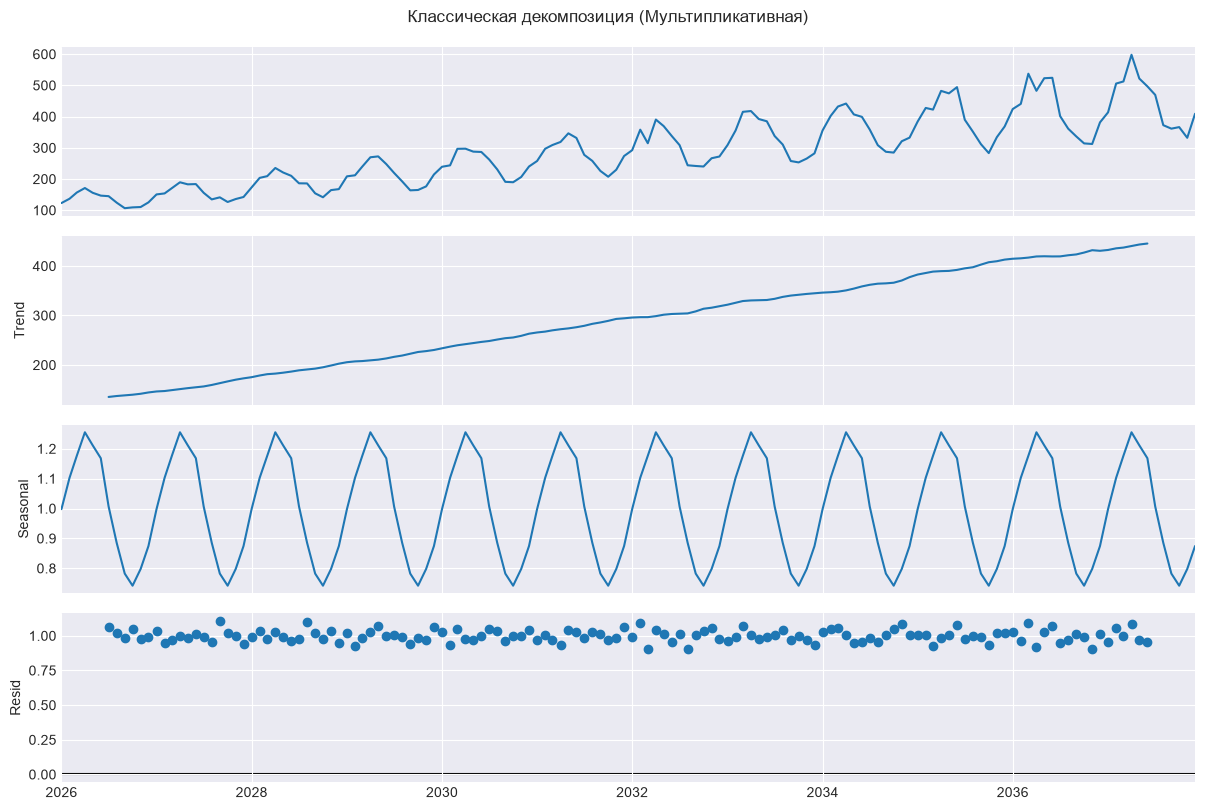

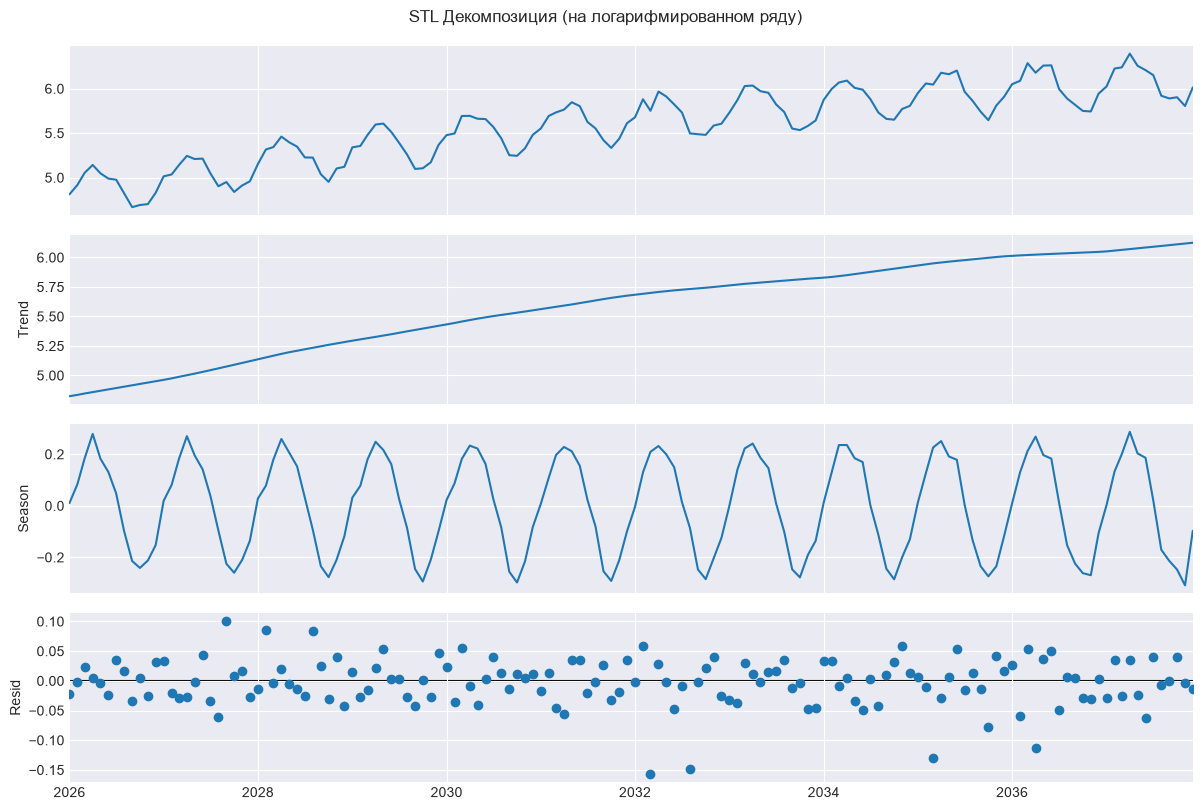

In [8]:
# 1. Классическая декомпозиция (МУЛЬТИПЛИКАТИВНАЯ)
res_classic = seasonal_decompose(ts, model='multiplicative', period=12)
fig = res_classic.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Классическая декомпозиция (Мультипликативная)', y=1.02)
plt.show()

# 2. STL (АДДИТИВНАЯ, поэтому берем логарифм)
log_ts = np.log(ts)
stl = STL(log_ts, period=12, robust=True)
res_stl = stl.fit()
fig = res_stl.plot()
fig.set_size_inches(12, 8)
fig.suptitle('STL Декомпозиция (на логарифмированном ряду)', y=1.02)
plt.show()

*   **MSTL:** у нашего ряда только одна сезонность (12 месяцев), поэтому MSTL не даст принципиально нового результата. Но для проверки запустим его.

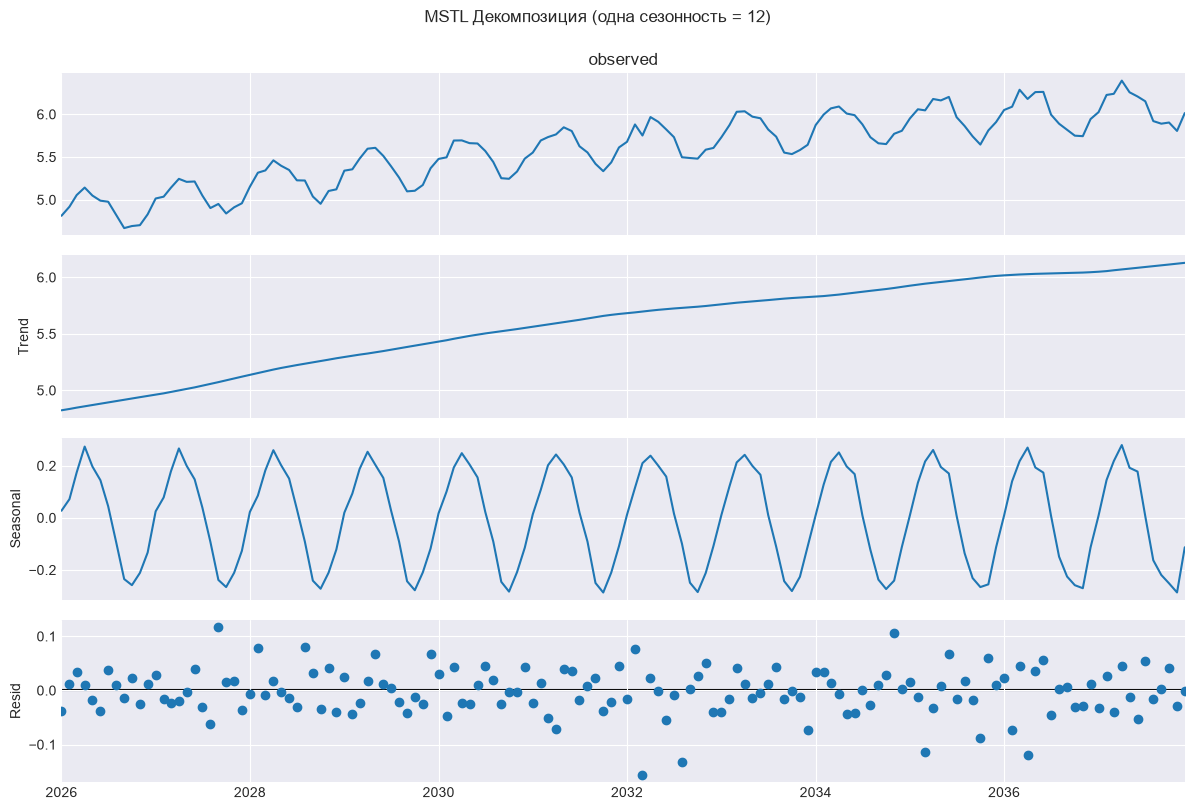

In [9]:
mstl = MSTL(log_ts, periods=(12,), stl_kwargs={"robust": True})
res_mstl = mstl.fit()
fig = res_mstl.plot()
fig.set_size_inches(12, 8)
fig.suptitle('MSTL Декомпозиция (одна сезонность = 12)', y=1.02)
plt.show()

**4. Сравнение остатков:**
Сравним дисперсию остатков и построим ACF (автокоррелограмму). Если остаток "чистый", на ACF не должно быть высоких пиков на лаге 12.

=== ДИСПЕРСИЯ ОСТАТКОВ ===
Классическая (мультипликативная): 0.00186
STL (лог-шкала):                  0.00157
MSTL (лог-шкала):                 0.00179


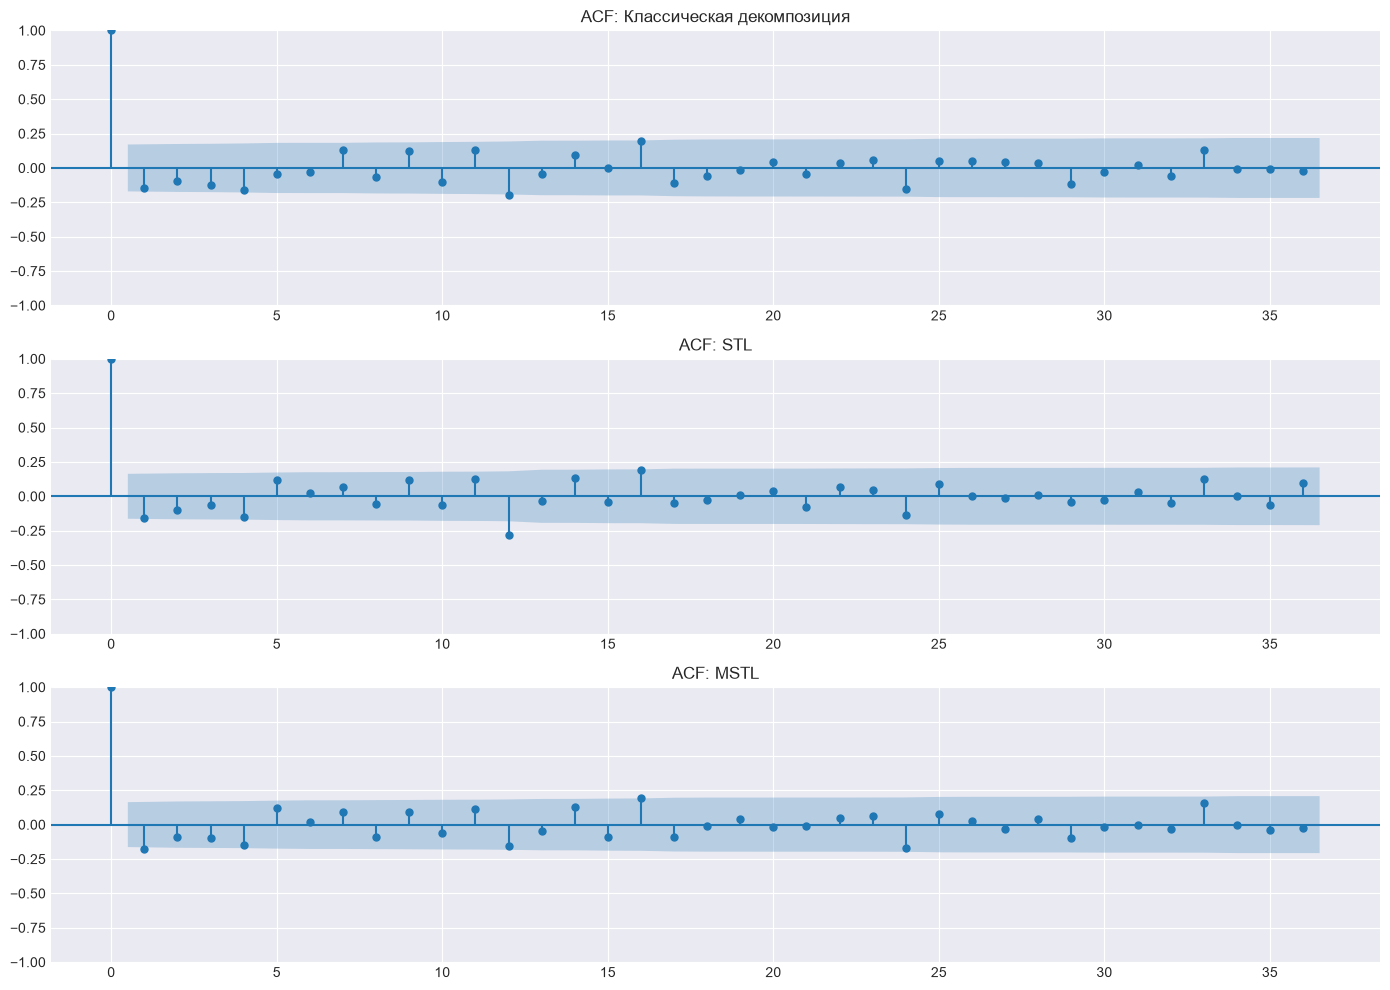

In [10]:
# Берем остатки (для STL и MSTL остатки в лог-шкале)
resid_classic = res_classic.resid
resid_stl = res_stl.resid
resid_mstl = res_mstl.resid

print("=== ДИСПЕРСИЯ ОСТАТКОВ ===")
print(f"Классическая (мультипликативная): {np.var(resid_classic.dropna()):.5f}")
print(f"STL (лог-шкала):                  {np.var(resid_stl.dropna()):.5f}")
print(f"MSTL (лог-шкала):                 {np.var(resid_mstl.dropna()):.5f}")

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
plot_acf(resid_classic.dropna(), lags=36, ax=axes[0], title='ACF: Классическая декомпозиция')
plot_acf(resid_stl.dropna(), lags=36, ax=axes[1], title='ACF: STL')
plot_acf(resid_mstl.dropna(), lags=36, ax=axes[2], title='ACF: MSTL')
plt.tight_layout()
plt.show()

**5. Подбор параметров STL (`season`, `trend`):**
*   **`season` (окно сглаживания сезонности):** По умолчанию берется 7. Если сезонность стабильна (как у нас), окно можно сделать больше (например, 13). Это сделает сезонный профиль более жестким и менее подверженным случайным колебаниям.
*   **`trend` (окно сглаживания тренда):** Если сделать его слишком маленьким, тренд будет "дрожать" от шума. Если слишком большим — тренд станет прямой линией и "съест" реальные изменения. Возьмем 25 (примерно 2 года) для гладкого тренда.

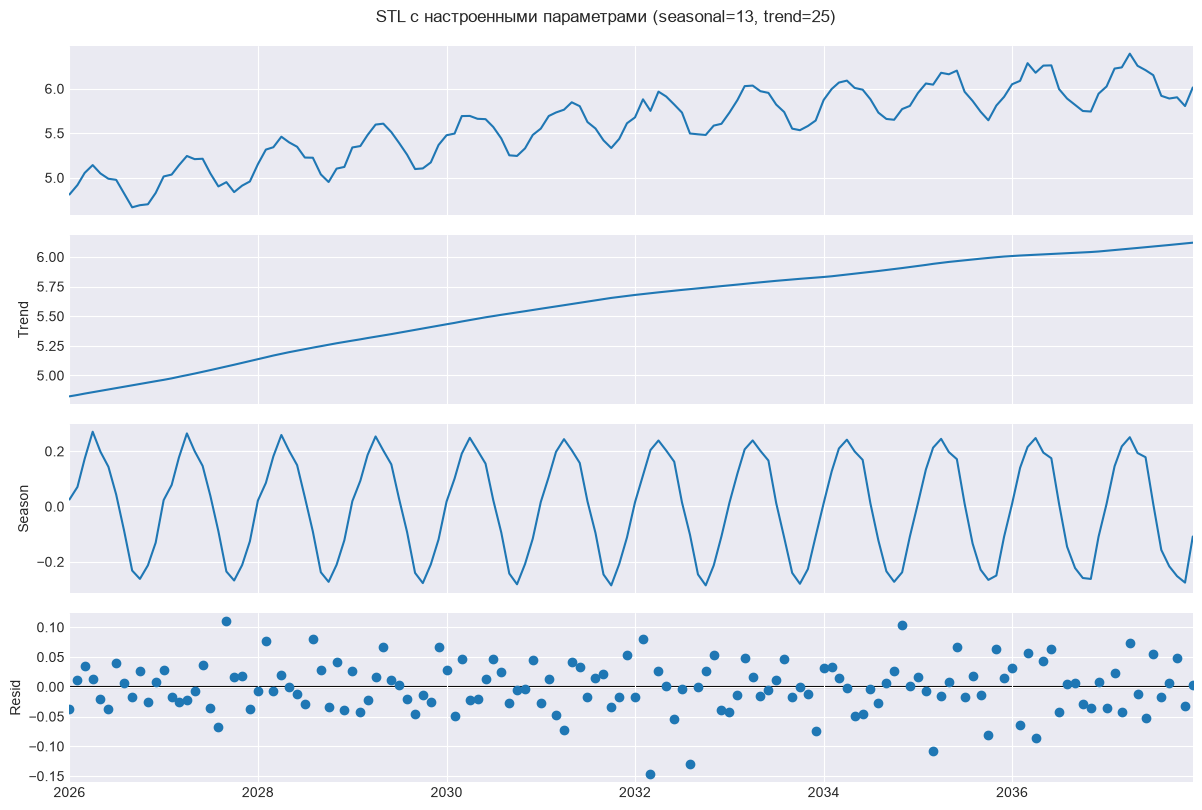

Дисперсия остатка настроенного STL: 0.00176


In [11]:
# Запускаем STL с подобранными параметрами
# Внимание: окна должны быть нечетными!
custom_stl = STL(log_ts, period=12, seasonal=13, trend=25, robust=True)
res_custom = custom_stl.fit()

fig = res_custom.plot()
fig.set_size_inches(12, 8)
fig.suptitle('STL с настроенными параметрами (seasonal=13, trend=25)', y=1.02)
plt.show()

print(f"Дисперсия остатка настроенного STL: {np.var(res_custom.resid.dropna()):.5f}")

**6. Краткий отчет и выводы:**

**Какой метод лучше подходит?**
Для данного ряда лучшим выбором является **STL-декомпозиция с подобранными параметрами**. 

*   **Классическая декомпозиция** дает хороший базовый результат, но она сильно страдает от краевых эффектов (первые и последние 6 месяцев не имеют оценки тренда). Кроме того, она жестко фиксирует сезонный профиль на все 12 лет.
*   **STL** (с параметрами `seasonal=13`, `trend=25`) дает более гладкий и интерпретируемый тренд, а также позволяет сезонности слегка адаптироваться. Благодаря `robust=True` выбросы не искажают общую картину. 
*   **MSTL** показал себя идентично STL, так как в ряду только одна сезонность. Его применение оправдано только для рядов с несколькими периодами (например, суточным и недельным).

**Анализ остатков (ACF):**
На графиках ACF для всех трех методов пики на лагах 12, 24, 36 и т.д. отсутствуют. Остатки находятся в пределах синей зоны (доверительного интервала), что говорит о том, что сезонность была успешно извлечена, и остаток представляет собой белый шум. Дисперсия остатков у всех методов примерно одинакова (разница из-за лог-преобразования).